In [14]:
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
import spacy
import re
from difflib import unified_diff


In [3]:

url = (
    "https://huggingface.co/datasets/reciTAL/mlsum/resolve/"
    "a018d1827f8bd5c4369ee7c5a54845c91c89ac28/"
    "es/mlsum-test.parquet"
)

ruta = Path("mlsum_es_test.parquet")

if not ruta.exists():
    respuesta = requests.get(url, timeout=180)
    respuesta.raise_for_status()
    ruta.write_bytes(respuesta.content)

df_original = pd.read_parquet(ruta)

print("Artículos descargados:", len(df_original))
print("Columnas:", df_original.columns.tolist())

display(df_original[["title", "date", "text"]].head(3))

Artículos descargados: 13920
Columnas: ['text', 'summary', 'topic', 'url', 'title', 'date']


,title,date,text
0,Un año de la carambola que lo cambió todo,01/06/2019,"Despedida de Rajoy, tras perder la votación de..."
1,Día de las Fuerzas Armadas: Sevilla homenajea ...,01/06/2019,Si no puede ver la retransmisión del desfile e...
2,"‘Ceebu jën’, el plato de los cuatro continentes",01/06/2019,Cocina como si danzara. Da pasos grandes y más...


In [ ]:
df = df_original.copy()
df["documento_id"] = [
    f"MLSUM_ES_TEST_{i:05d}" for i in range(len(df))
]

# Conservamos el texto original y creamos una versión limpia
df["texto_limpio"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["n_palabras"] = df["texto_limpio"].str.split().str.len()

# Eliminar vacíos y textos con menos de 5 palabras
n_original = len(df)
df = df[df["n_palabras"] >= 5].copy()
n_cortos = n_original - len(df)

# Detectar duplicados ignorando mayúsculas y espacios normalizados.
df["clave_duplicado"] = df["texto_limpio"].str.casefold()
n_antes = len(df)
df = df.drop_duplicates("clave_duplicado").copy()
n_duplicados = n_antes - len(df)

if len(df) < 1000:
    raise ValueError("No hay sufiencientes articulos para la muestra.")

muestra = df.sample(n=1000, random_state=42).reset_index(drop=True)

print("Artículos originales:", n_original)
print("Vacíos o textos cortos eliminados:", n_cortos)
print("Duplicados eliminados:", n_duplicados)
print("Artículos disponibles después de limpiar:", len(df))
print("Artículos seleccionados:", len(muestra))

Artículos originales: 13920
Vacíos o muy cortos eliminados: 0
Duplicados eliminados: 241
Artículos disponibles después de limpiar: 13679
Artículos seleccionados: 1000


,Palabras por artículo
count,1000.000000
mean,782.698000
std,507.967004
min,53.000000
25%,480.750000
50%,714.500000
75%,960.000000
max,6510.000000


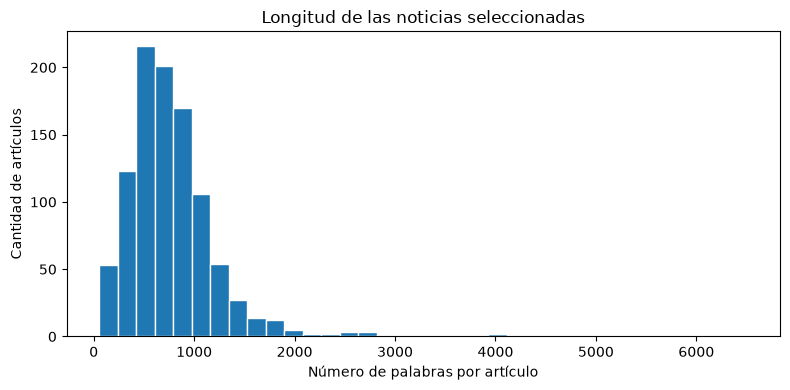

In [5]:

display(
    muestra["n_palabras"]
    .describe()
    .rename("Palabras por artículo")
    .to_frame()
)

plt.figure(figsize=(8, 4))
plt.hist(muestra["n_palabras"], bins=35, edgecolor="white")
plt.xlabel("Número de palabras por artículo")
plt.ylabel("Cantidad de artículos")
plt.title("Longitud de las noticias seleccionadas")
plt.tight_layout()
plt.show()

Medimos los tokemns sobre la variable muestra que se creó.

In [ ]:

NOMBRE_MODELO = (
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

modelo_embeddings = SentenceTransformer(NOMBRE_MODELO)
tokenizador = modelo_embeddings.tokenizer
limite_tokens = modelo_embeddings.max_seq_length

# Contamos la longitud completa
def contar_tokens(texto):
    return len(
        tokenizador(
            texto,
            add_special_tokens=True,
            truncation=False,
            verbose=False
        )["input_ids"]
    )

muestra["n_tokens"] = muestra["texto_limpio"].apply(contar_tokens)

resumen_tokens = pd.Series({
    "Artículos": len(muestra),
    "Límite del modelo": limite_tokens,
    "Tokens promedio": muestra["n_tokens"].mean(),
    "Mediana de tokens": muestra["n_tokens"].median(),
    "Máximo de tokens": muestra["n_tokens"].max(),
    "Artículos que exceden el límite":
        (muestra["n_tokens"] > limite_tokens).sum(),
    "Porcentaje que excede el límite":
        100 * (muestra["n_tokens"] > limite_tokens).mean()
})

display(resumen_tokens.to_frame("Resultado").round(2))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2269.52it/s]


,Resultado
Artículos,1000.00
Límite del modelo,128.00
Tokens promedio,1109.18
Mediana de tokens,1000.50
Máximo de tokens,9613.00
Artículos que exceden el límite,992.00
Porcentaje que excede el límite,99.20


In [ ]:
nlp = spacy.blank("es")
nlp.add_pipe("sentencizer")


def dividir_oracion_larga(oracion):
    """Divide entre palabras solo cuando la oración supera el límite."""
    partes = []
    actual = ""

    for palabra in oracion.split():
        candidato = f"{actual} {palabra}".strip()

        if contar_tokens(candidato) <= limite_tokens:
            actual = candidato
        else:
            if actual:
                partes.append(actual)

            # Detectar caso excepcional sin truncarlo.
            if contar_tokens(palabra) > limite_tokens:
                raise ValueError(
                    f"Una palabra supera el límite; revisar: {palabra[:80]}"
                )

            actual = palabra

    if actual:
        partes.append(actual)

    return partes


def segmentar_documento(doc):
    """Agrupa oraciones consecutivas, sin solapamiento."""
    bloques = []
    actual = ""
    oraciones_divididas = 0

    for sentencia in doc.sents:
        oracion = " ".join(sentencia.text.split())

        if not oracion:
            continue

        if contar_tokens(oracion) > limite_tokens:
            oraciones_divididas += 1
            unidades = dividir_oracion_larga(oracion)
        else:
            unidades = [oracion]

        for unidad in unidades:
            candidato = f"{actual} {unidad}".strip()

            if contar_tokens(candidato) <= limite_tokens:
                actual = candidato
            else:
                bloques.append(actual)
                actual = unidad

    if actual:
        bloques.append(actual)

    return bloques, oraciones_divididas

In [ ]:
# Reiniciar los resultados para evitar registros de ejecuciones anteriores
registros = []
total_oraciones_divididas = 0
cambios_de_espaciado = []


def sin_espacios(texto):
    return re.sub(r"\s+", "", texto)


documentos = nlp.pipe(
    muestra["texto_limpio"].tolist(),
    batch_size=32
)

for fila, doc in zip(muestra.to_dict("records"), documentos):

    bloques, n_divididas = segmentar_documento(doc)
    total_oraciones_divididas += n_divididas
    
    # Comprobar que se conserva el contenido
    reconstruido = " ".join(bloques)
    original = fila["texto_limpio"]

    if reconstruido != original:
        if sin_espacios(reconstruido) == sin_espacios(original):
            cambios_de_espaciado.append(fila["documento_id"])
        else:
            diferencia = "\n".join(
                unified_diff(
                    original.split(),
                    reconstruido.split(),
                    fromfile="original",
                    tofile="reconstruido",
                    lineterm=""
                )
            )

            raise ValueError(
                f"Cambió el contenido en {fila['documento_id']}:\n"
                f"{diferencia[:2000]}"
            )

    # Registrar los segmentos y conservar su artículo de origen.
    for numero, texto in enumerate(bloques, start=1):
        registros.append({
            "documento_id": fila["documento_id"],
            "segmento_id": (
                f"{fila['documento_id']}_S{numero:03d}"
            ),
            "title": fila.get("title", ""),
            "date": fila.get("date", ""),
            "url": fila.get("url", ""),
            "texto": texto,
            "n_palabras": len(texto.split()),
            "n_tokens": contar_tokens(texto)
        })

segmentos_brutos = pd.DataFrame(registros)

# Validaciones finales.
assert not segmentos_brutos.empty, "No se generaron segmentos."

assert segmentos_brutos["n_tokens"].max() <= limite_tokens, (
    "Hay segmentos que exceden el límite de tokens."
)

assert segmentos_brutos["segmento_id"].is_unique, (
    "Hay identificadores de segmento repetidos."
)

print("Artículos procesados:", len(muestra))
print("Segmentos generados:", len(segmentos_brutos))
print("Oraciones que requirieron división:", total_oraciones_divididas)
print(
    "Artículos con cambios únicamente de espaciado:",
    len(cambios_de_espaciado)
)
print(
    "Máximo de tokens por segmento:",
    segmentos_brutos["n_tokens"].max()
)

display(segmentos_brutos.head())

Artículos procesados: 1000
Segmentos generados: 10988
Oraciones que requirieron división: 111
Artículos con cambios únicamente de espaciado: 702
Máximo de tokens por segmento: 128


,documento_id,segmento_id,title,date,url,texto,n_palabras,n_tokens
0,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S001,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,El pleno del Parlamento de Cataluña ha burlado...,54,66
1,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S002,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,La reunión debía iniciarse a las tres de la ta...,81,110
2,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S003,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,El PSC y el PP no han participado en la votaci...,54,71
3,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S004,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,Con el adelanto inesperado del pleno acordado ...,60,86
4,MLSUM_ES_TEST_13841,MLSUM_ES_TEST_13841_S005,El Parlament burla al Constitucional y aprueba...,12/11/2019,http://elpais.com/ccaa/2019/11/12/catalunya/15...,Esa suspensión impidió el debate de la moción ...,45,58


In [16]:
segmentos = segmentos_brutos.copy()

# Filtrar vacíos y segmentos con menos de cinco palabras.
n_inicial = len(segmentos)
segmentos = segmentos[segmentos["n_palabras"] >= 5].copy()
n_cortos = n_inicial - len(segmentos)

# Eliminar segmentos repetidos en el corpus.
segmentos["clave_duplicado"] = segmentos["texto"].str.casefold()

n_antes = len(segmentos)
segmentos = (
    segmentos
    .drop_duplicates("clave_duplicado")
    .drop(columns="clave_duplicado")
    .reset_index(drop=True)
)
n_duplicados = n_antes - len(segmentos)

assert len(segmentos) >= 500, "Revisar: quedaron menos de 500 segmentos."
assert segmentos["n_tokens"].max() <= limite_tokens
assert segmentos["segmento_id"].is_unique

resumen_segmentacion = pd.Series({
    "Artículos seleccionados": len(muestra),
    "Segmentos generados antes de filtrar": n_inicial,
    "Segmentos cortos eliminados": n_cortos,
    "Segmentos duplicados eliminados": n_duplicados,
    "Segmentos finales": len(segmentos),
    "Artículos con segmentos conservados":
        segmentos["documento_id"].nunique(),
    "Palabras promedio por segmento": segmentos["n_palabras"].mean(),
    "Tokens promedio por segmento": segmentos["n_tokens"].mean(),
    "Máximo de tokens por segmento": segmentos["n_tokens"].max(),
    "Segmentos que exceden el límite":
        (segmentos["n_tokens"] > limite_tokens).sum()
})

display(resumen_segmentacion.to_frame("Resultado").round(2))

,Resultado
Artículos seleccionados,1000.00
Segmentos generados antes de filtrar,10988.00
Segmentos cortos eliminados,4.00
Segmentos duplicados eliminados,40.00
Segmentos finales,10944.00
Artículos con segmentos conservados,1000.00
Palabras promedio por segmento,71.77
Tokens promedio por segmento,102.98
Máximo de tokens por segmento,128.00
Segmentos que exceden el límite,0.00


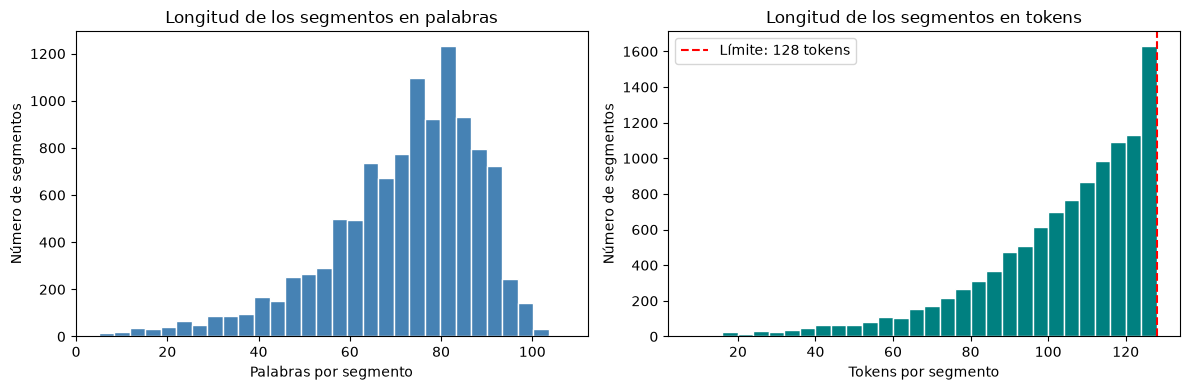

,n_palabras,n_tokens
count,10944.00,10944.00
mean,71.77,102.98
std,16.56,21.85
min,5.00,8.00
25%,63.00,92.00
50%,75.00,109.00
75%,84.00,120.00
max,107.00,128.00


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    segmentos["n_palabras"], bins=30,
    color="steelblue", edgecolor="white"
)
axes[0].set(
    title="Longitud de los segmentos en palabras",
    xlabel="Palabras por segmento",
    ylabel="Número de segmentos"
)

axes[1].hist(
    segmentos["n_tokens"], bins=30,
    color="teal", edgecolor="white"
)
axes[1].axvline(
    limite_tokens, color="red", linestyle="--",
    label=f"Límite: {limite_tokens} tokens"
)
axes[1].set(
    title="Longitud de los segmentos en tokens",
    xlabel="Tokens por segmento",
    ylabel="Número de segmentos"
)
axes[1].legend()

plt.tight_layout()
plt.show()

display(segmentos[["n_palabras", "n_tokens"]].describe().round(2))

In [ ]:
ejemplos = segmentos.sample(n=5, random_state=42)

for fila in ejemplos.itertuples():
    print(f"\n{fila.segmento_id} | {fila.n_tokens} tokens")
    print(f"Título: {fila.title}")
    print(fila.texto)
    print("-" * 70)

docs = segmentos["texto"].tolist()


MLSUM_ES_TEST_12913_S008 | 112 tokens
Título: William Nordhaus: “Hay que buscar un acuerdo internacional de países con un precio similar para el carbono”
Todavía no hemos hecho nada” R. Por esas complejidades yo prefiero la idea de un arancel uniforme para todas las importaciones de fuera del acuerdo en vez de medir el contenido de carbono de cada producto. No se trata de castigar la entrada de determinados bienes, sino de generar incentivos para participar. Así funciona el mercado único de la Unión Europea. Los países que están dentro tienen acuerdos preferentes en comercio y movimientos de capital frente a los que los países de fuera no pueden acceder.
----------------------------------------------------------------------

MLSUM_ES_TEST_10917_S004 | 94 tokens
Título: Cambio climático: La extraña batalla
A la última cita ya solo acudieron 70 de los 200 que firmaron el Acuerdo de París, y a la idea de revisar al alza la reducción de emisiones no se apuntan ni China ni Estados Unidos n